In [1]:
!pip install monai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 16.6 MB/s eta 0:00:00


In [2]:
import copy
import gc
import itertools
import math
import os
import random
import shutil
import tarfile
import time
from contextlib import nullcontext
from dataclasses import asdict, dataclass, replace
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.colors import ListedColormap
from monai.inferers import sliding_window_inference
from scipy import ndimage as ndi
from sklearn.model_selection import train_test_split
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

In [3]:
@dataclass
class Config:
    seed: int = 7
    input_root: str = "/kaggle/input/datasets/dschettler8845/brats-2021-task1"
    output_root: str = os.environ.get("MOREG_OUTPUT", "/kaggle/working/moreg")
    smoke_test: bool = False  # set to False for the full run
    run_training: bool = True
    run_baseline: bool = False
    run_student: bool = False
    run_missing_modalities: bool = False
    resume_path: str = ""
    roi: tuple = (96, 96, 96)
    base: int = 24
    batch_size: int = 1
    accumulate: int = 2
    epochs: int = 125
    student_epochs: int = 40
    max_train_batches: int = 250
    workers: int = 2
    lr: float = 3e-4
    min_lr: float = 1e-6
    weight_decay: float = 1e-4
    warmup_epochs: int = 10
    val_every: int = 5
    patience_checks: int = 15
    ema_decay: float = 0.99
    amp: bool = True
    train_fraction: float = 0.70
    val_fraction: float = 0.15
    foreground_prob: float = 0.75
    cache_gb: float = 8.0
    overlap: float = 0.5
    sw_batch_size: int = 1
    tta: bool = False
    threshold: float = 0.5
    surface_tolerance_mm: float = 1.0
    bootstrap_samples: int = 2000
    save_nifti_count: int = 3
    deterministic: bool = False


cfg = Config()
if cfg.smoke_test:
    cfg = replace(
        cfg,
        roi=(32, 32, 32),
        base=4,
        epochs=2,
        student_epochs=2,
        max_train_batches=3,
        workers=0,
        accumulate=2,
        val_every=1,
        warmup_epochs=1,
        bootstrap_samples=100,
        cache_gb=0.05,
    )

assert 0 < cfg.train_fraction < 1 and 0 < cfg.val_fraction < 1 - cfg.train_fraction
assert all(v >= 16 and v % 8 == 0 for v in cfg.roi)
assert cfg.epochs > 0 and cfg.accumulate > 0
OUT = Path(cfg.output_root) / ("smoke" if cfg.smoke_test else "full")
OUT.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODALITIES = ("t1", "t1ce", "t2", "flair")
REGIONS = ("WT", "TC", "ET")


def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = not cfg.deterministic
    torch.backends.cudnn.deterministic = cfg.deterministic
    torch.use_deterministic_algorithms(cfg.deterministic, warn_only=True)


seed_all(cfg.seed)

In [4]:
def amp_context():
    return (
        torch.autocast("cuda", dtype=torch.float16)
        if cfg.amp and DEVICE.type == "cuda"
        else nullcontext()
    )


def atomic_write(path, writer):
    path = Path(path)
    temp = path.with_name(path.name + ".tmp")
    with open(temp, "wb") as handle:
        writer(handle)
    temp.replace(path)


def atomic_npy(path, array):
    atomic_write(path, lambda handle: np.save(handle, array))


def atomic_npz(path, **arrays):
    atomic_write(path, lambda handle: np.savez(handle, **arrays))


def atomic_csv(frame, path):
    atomic_write(path, lambda handle: frame.to_csv(handle, index=False))


if DEVICE.type == "cpu" and not cfg.smoke_test:
    print("WARNING: Full 3D training on CPU will be very slow. Enable a Kaggle GPU.")

In [5]:
def extract_archive(archive, dest):
    archive, dest = Path(archive), Path(dest)

    marker = dest / f".complete_{archive.stat().st_size}"
    if marker.exists():
        return
    if dest.exists():
        shutil.rmtree(dest)
    dest.mkdir(parents=True)
    with tarfile.open(archive, "r:*") as tf:
        members = tf.getmembers()
        for m in members:
            target = (dest / m.name).resolve()
            if not target.is_relative_to(dest.resolve()) or not (m.isfile() or m.isdir()):
                raise ValueError(f"Unsafe archive member: {m.name}")
        required = sum(m.size for m in members if m.isfile())
        if shutil.disk_usage(dest).free < required + 1024**3:
            raise OSError(f"Insufficient free disk to extract {archive.name}")
        tf.extractall(dest, members=members, filter="data")
    marker.touch()


def discover(root):
    result = {}
    anchors = sorted(Path(root).rglob("*_flair.nii*"))
    for f in anchors:
        if not (f.name.endswith(".nii") or f.name.endswith(".nii.gz")):
            continue
        cid = f.name.split("_flair.nii")[0]
        paths = {}
        for suffix in (*MODALITIES, "seg"):
            matches = [f.parent / f"{cid}_{suffix}{ext}" for ext in (".nii.gz", ".nii")]
            existing = [p for p in matches if p.is_file()]
            if len(existing) != 1:
                raise ValueError(f"{cid}: expected exactly one {suffix}, found {existing}")
            paths[suffix] = str(existing[0])
        if cid in result:
            raise ValueError(f"Duplicate patient {cid} under {root}; attach one dataset copy.")
        result[cid] = {
            "case_id": cid,
            "image": [paths[m] for m in MODALITIES],
            "label": paths["seg"],
        }
    return result


DATA_ROOT = Path(cfg.input_root)
TRAIN_TAR = DATA_ROOT / "BraTS2021_Training_Data.tar"
FIX_TARS = [DATA_ROOT / "BraTS2021_00495.tar", DATA_ROOT / "BraTS2021_00621.tar"]

for archive in (TRAIN_TAR, *FIX_TARS):
    if not archive.is_file():
        raise FileNotFoundError(f"Missing BraTS 2021 archive: {archive}")

extract_archive(TRAIN_TAR, OUT / "extracted" / "training")
case_map = discover(OUT / "extracted" / "training")

# Corrected cases replace the matching entries from the main archive.
for archive in FIX_TARS:
    fix_dir = OUT / "extracted" / archive.stem
    extract_archive(archive, fix_dir)
    case_map.update(discover(fix_dir))

cases = [case_map[k] for k in sorted(case_map)]
if not cases:
    raise FileNotFoundError(f"No complete labeled cases found under {DATA_ROOT}")
if cfg.smoke_test:
    cases = cases[: min(12, len(cases))]
if len(cases) < 8:
    raise ValueError("At least 8 patients are required for meaningful three-way splitting.")

PREPROCESS_VERSION = "ras-4ch-zscore-braincrop"

In [6]:
def load_case(case):
    ims = [nib.as_closest_canonical(nib.load(p)) for p in case["image"]]
    seg = nib.as_closest_canonical(nib.load(case["label"]))
    shape, affine = ims[0].shape, ims[0].affine
    if len(shape) != 3:
        raise ValueError(f"{case['case_id']}: expected 3D NIfTI, found {shape}")
    for im in [*ims, seg]:
        if im.shape != shape or not np.allclose(im.affine, affine, atol=1e-4):
            raise ValueError(f"{case['case_id']}: modalities/mask geometry mismatch")

    x = np.stack([im.get_fdata(dtype=np.float32) for im in ims], axis=0)
    raw_y = seg.get_fdata(dtype=np.float32)
    if not np.isfinite(x).all() or not np.isfinite(raw_y).all():
        raise ValueError("Non-finite NIfTI values")
    if not set(np.unique(raw_y)).issubset({0.0, 1.0, 2.0, 4.0}):
        raise ValueError(f"Unexpected labels: {np.unique(raw_y)}")
    y = raw_y.astype(np.uint8)
    brain = np.any(x != 0, axis=0)
    if not brain.any():
        raise ValueError("All modalities are empty")
    coords = np.where(brain)
    lo = [max(0, int(c.min()) - 2) for c in coords]
    hi = [min(shape[a], int(c.max()) + 3) for a, c in enumerate(coords)]
    box = tuple(slice(a, b) for a, b in zip(lo, hi))
    if np.count_nonzero(y[box]) != np.count_nonzero(y):
        raise ValueError(f"{case['case_id']}: label outside image foreground crop")
    x, y = x[(slice(None),) + box].copy(), y[box].copy()
    for m in range(4):
        mask = x[m] != 0
        if not mask.any():
            raise ValueError(f"{case['case_id']}: empty {MODALITIES[m]}")
        values = x[m][mask]
        low, high = np.percentile(values, [0.5, 99.5])
        values = np.clip(values, low, high)
        x[m][mask] = (values - values.mean()) / max(float(values.std()), 1e-6)
    spacing = np.asarray(nib.affines.voxel_sizes(affine), dtype=float)
    direction = affine[:3, :3] / spacing[None, :]
    if not np.allclose(direction.T @ direction, np.eye(3), atol=1e-4):
        raise ValueError(
            "Sheared affine: resample to an orthogonal grid before distance evaluation"
        )
    meta = dict(
        case_id=case["case_id"],
        shape=list(shape),
        lo=lo,
        hi=hi,
        spacing=spacing.tolist(),
        affine=affine.tolist(),
    )
    assert x.shape[0] == 4 and x.ndim == 4 and x.shape[1:] == y.shape
    return x, y, meta


CACHE = OUT / "cache"
CACHE.mkdir(exist_ok=True)
cache_limit = int(cfg.cache_gb * 1024**3)
cache_used = sum(p.stat().st_size for p in CACHE.glob("*") if p.is_file())

In [7]:
def cache_files(case):
    # (image, label, meta)
    stem = f"{case['case_id']}_{PREPROCESS_VERSION}"
    return tuple(CACHE / f"{stem}_{part}" for part in ("x.npy", "y.npy", "meta.npz"))


def load_meta(path):
    with np.load(path) as saved:
        return {key: saved[key].tolist() for key in saved.files}


def get_case(case, allow_cache=False):
    global cache_used
    x_path, y_path, meta_path = cache_files(case)

    if meta_path.exists():
        return np.load(x_path, mmap_mode="r"), np.load(y_path, mmap_mode="r"), load_meta(meta_path)
    x, y, meta = load_case(case)
    size = x.nbytes + y.nbytes + 10000
    has_room = cache_used + size <= cache_limit
    has_disk = shutil.disk_usage(CACHE).free > size + 2 * 1024**3
    if allow_cache and has_room and has_disk:
        atomic_npy(x_path, x)
        atomic_npy(y_path, y)
        atomic_npz(meta_path, **meta)
        cache_used += size
    return x, y, meta


audit_rows = []
for c in tqdm(cases, desc="Audit geometry, labels, and tumor volumes"):
    x, y, meta = get_case(c, allow_cache=True)
    audit_rows.append(
        dict(
            case_id=c["case_id"],
            ET_present=bool((y == 4).any()),
            WT_ml=float(np.count_nonzero(y) * np.prod(meta["spacing"]) / 1000),
            shape=str(meta["shape"]),
            spacing=str(meta["spacing"]),
        )
    )
audit = pd.DataFrame(audit_rows)
audit.to_csv(OUT / "data_audit.csv", index=False)
print(f"Validated {len(cases)} patients; disk cache {cache_used/1024**3:.2f} GiB")
display(audit.head())

Audit geometry, labels, and tumor volumes:   0%|          | 0/1251 [00:00<?, ?it/s]

Validated 1251 patients; disk cache 4.98 GiB


,case_id,ET_present,WT_ml,shape,spacing
0,BraTS2021_00000,True,57.305,"[240, 240, 155]","[1.0, 1.0, 1.0]"
1,BraTS2021_00002,True,190.594,"[240, 240, 155]","[1.0, 1.0, 1.0]"
2,BraTS2021_00003,True,99.239,"[240, 240, 155]","[1.0, 1.0, 1.0]"
3,BraTS2021_00005,True,124.783,"[240, 240, 155]","[1.0, 1.0, 1.0]"
4,BraTS2021_00006,True,137.911,"[240, 240, 155]","[1.0, 1.0, 1.0]"


split
test     188
train    875
val      188
dtype: int64


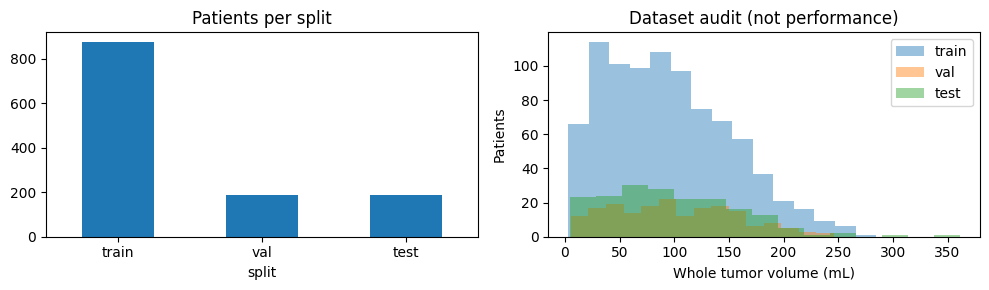

In [8]:
SPLIT_NAMES = ("train", "val", "test")
split_path = OUT / "patient_split.csv"
protocol_path = OUT / "split_protocol.npz"
ids = sorted(c["case_id"] for c in cases)
strata = audit.set_index("case_id")["ET_present"].to_dict()


def partition(items, test_size, seed):
    labels = [strata[i] for i in items]
    try:
        return train_test_split(items, test_size=test_size, random_state=seed, stratify=labels)
    except ValueError as exc:
        print("ET stratification unavailable for this split; using seeded random partition:", exc)
        return train_test_split(items, test_size=test_size, random_state=seed)


def same_arrays(first, second):
    return first.keys() == second.keys() and all(
        np.array_equal(first[key], second[key]) for key in first
    )


protocol = dict(
    ids=np.array(ids),
    seed=cfg.seed,
    train_fraction=cfg.train_fraction,
    val_fraction=cfg.val_fraction,
)
if split_path.exists():
    with np.load(protocol_path) as saved:
        saved_protocol = {key: saved[key] for key in saved.files}
    if not same_arrays(saved_protocol, protocol):
        raise ValueError(
            "Dataset/split config changed. Choose a new output_root, do not overwrite test membership."
        )
    splits = pd.read_csv(split_path, dtype={"case_id": str})
else:
    train_ids, rest = partition(ids, 1 - cfg.train_fraction, cfg.seed)
    val_fraction_of_rest = round(
        (1 - cfg.train_fraction - cfg.val_fraction) / (1 - cfg.train_fraction), 6
    )
    val_ids, test_ids = partition(rest, val_fraction_of_rest, cfg.seed + 1)
    splits = pd.DataFrame(
        [
            (case_id, name)
            for name, group in zip(SPLIT_NAMES, (train_ids, val_ids, test_ids))
            for case_id in group
        ],
        columns=["case_id", "split"],
    ).sort_values("case_id")
    splits.to_csv(split_path, index=False)
    atomic_npz(protocol_path, **protocol)
assert splits.case_id.is_unique and set(splits.case_id) == set(ids)
assert set(splits.split) == set(SPLIT_NAMES)

# Exact record of patient-to-split membership, stored in checkpoints and compared with numpy.
_ordered = splits.sort_values("case_id")
SPLIT_RECORD = dict(
    ids=_ordered.case_id.to_numpy(dtype=str),
    codes=_ordered.split.map({name: i for i, name in enumerate(SPLIT_NAMES)}).to_numpy(np.uint8),
)

case_by_id = {c["case_id"]: c for c in cases}
files = {
    name: [case_by_id[i] for i in splits.loc[splits.split == name, "case_id"]]
    for name in SPLIT_NAMES
}
print(splits.groupby("split").size())

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
splits.split.value_counts().plot.bar(ax=ax[0], title="Patients per split", rot=0)
for name in SPLIT_NAMES:
    volumes = audit[audit.case_id.isin([c["case_id"] for c in files[name]])].WT_ml
    ax[1].hist(volumes, bins=15, alpha=0.45, label=name)
ax[1].set(
    xlabel="Whole tumor volume (mL)", ylabel="Patients", title="Dataset audit (not performance)"
)
ax[1].legend()
fig.tight_layout()
fig.savefig(OUT / "split_audit.png", dpi=160)
plt.show()

In [9]:
def regions_from_labels(y):
    return np.stack([y > 0, (y == 1) | (y == 4), y == 4]).astype(np.float32)


class PatchDataset(Dataset):
    def __init__(self, case_list, augment=True):
        self.cases = case_list
        self.augment = augment

    def __len__(self):
        return len(self.cases)

    def __getitem__(self, index):
        x, y, meta = get_case(self.cases[index])
        pad = [(0, max(0, r - s)) for r, s in zip(cfg.roi, y.shape)]
        x = np.pad(x, [(0, 0)] + pad)
        y = np.pad(y, pad)
        if np.random.rand() < cfg.foreground_prob and np.any(y > 0):
            present = [v for v in (1, 2, 4) if np.any(y == v)]
            eligible = y == int(np.random.choice(present))
        else:
            eligible = (np.any(x != 0, axis=0)) & (y == 0)
            if not eligible.any():
                eligible = np.ones_like(y, dtype=bool)
        indices = np.flatnonzero(eligible)
        center = np.unravel_index(indices[np.random.randint(len(indices))], y.shape)
        start = [int(np.clip(c - r // 2, 0, s - r)) for c, r, s in zip(center, cfg.roi, y.shape)]
        sl = tuple(slice(a, a + r) for a, r in zip(start, cfg.roi))
        x = x[(slice(None),) + sl].copy()
        y = y[sl].copy()
        if self.augment:
            for axis in range(3):
                if np.random.rand() < 0.5:
                    x = np.flip(x, axis + 1)
                    y = np.flip(y, axis)
            # Right-angle rotations retain label integrity. Only rotate equal-sized dimensions.
            if cfg.roi[0] == cfg.roi[1] and np.random.rand() < 0.3:
                k = np.random.randint(1, 4)
                x = np.rot90(x, k, (1, 2))
                y = np.rot90(y, k, (0, 1))
            if np.random.rand() < 0.5:
                gain = np.random.uniform(0.85, 1.15, (4, 1, 1, 1))
                bias = np.random.uniform(-0.1, 0.1, (4, 1, 1, 1))
                x = np.where(x != 0, x * gain + bias, 0)
            if np.random.rand() < 0.2:
                x = x + np.random.normal(0, 0.05, x.shape) * (x != 0)
        return dict(
            image=torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32)),
            label=torch.from_numpy(np.ascontiguousarray(regions_from_labels(y))),
            case_id=meta["case_id"],
        )


def seed_worker(worker_id):
    seed = torch.initial_seed() % 2**32
    np.random.seed(seed)
    random.seed(seed)


def make_train_loader(epoch):
    g = torch.Generator().manual_seed(cfg.seed + epoch)
    return DataLoader(
        PatchDataset(files["train"]),
        batch_size=cfg.batch_size,
        shuffle=True,
        num_workers=cfg.workers,
        pin_memory=DEVICE.type == "cuda",
        worker_init_fn=seed_worker,
        generator=g,
        persistent_workers=False,
    )


sample = PatchDataset(files["train"])[0]
assert sample["image"].shape == (4, *cfg.roi) and sample["label"].shape == (3, *cfg.roi)
assert torch.all(sample["label"][2] <= sample["label"][1]) and torch.all(
    sample["label"][1] <= sample["label"][0]
)
print("Patch:", sample["image"].shape, sample["label"].shape)

Patch: torch.Size([4, 96, 96, 96]) torch.Size([3, 96, 96, 96])


In [10]:
def norm(c):
    return nn.GroupNorm(math.gcd(c, 8), c)


class SE(nn.Module):
    def __init__(self, c):
        super().__init__()
        h = max(c // 4, 4)
        self.net = nn.Sequential(
            nn.AdaptiveAvgPool3d(1), nn.Conv3d(c, h, 1), nn.SiLU(), nn.Conv3d(h, c, 1), nn.Sigmoid()
        )

    def forward(self, x):
        return x * self.net(x)


class ResBlock(nn.Module):
    def __init__(self, ci, co, stride=1, attention=True):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv3d(ci, co, 3, stride, padding=1, bias=False),
            norm(co),
            nn.SiLU(),
            nn.Conv3d(co, co, 3, padding=1, bias=False),
            norm(co),
            SE(co) if attention else nn.Identity(),
        )
        self.skip = (
            nn.Conv3d(ci, co, 1, stride, bias=False) if ci != co or stride != 1 else nn.Identity()
        )

    def forward(self, x):
        return F.silu(self.body(x) + self.skip(x))


class ModalityFusion(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.stems = nn.ModuleList(
            [
                nn.Sequential(nn.Conv3d(1, c, 3, padding=1, bias=False), norm(c), nn.SiLU())
                for _ in range(4)
            ]
        )
        self.scores = nn.ModuleList([nn.Conv3d(c, 1, 1) for _ in range(4)])
        self.out = ResBlock(c + 4, c)

    def forward(self, x, a):
        fs = torch.stack([stem(x[:, m : m + 1]) for m, stem in enumerate(self.stems)], dim=1)
        scores = torch.stack([sc(fs[:, m]) for m, sc in enumerate(self.scores)], dim=1).float()
        scores = scores.masked_fill(~a.bool()[:, :, None, None, None, None], -1e4)
        w = scores.softmax(dim=1).to(fs.dtype)
        fused = (w * fs).sum(dim=1)
        available = a[:, :, None, None, None].expand(-1, -1, *x.shape[2:]).to(fused.dtype)
        return self.out(torch.cat([fused, available], 1))


class Context(nn.Module):
    def __init__(self, c):
        super().__init__()
        h = c // 2
        self.branches = nn.ModuleList(
            [
                nn.Sequential(
                    nn.Conv3d(c, h, 3, padding=d, dilation=d, bias=False), norm(h), nn.SiLU()
                )
                for d in (1, 2, 3)
            ]
        )
        self.project = nn.Sequential(nn.Conv3d(h * 3, c, 1, bias=False), norm(c))

    def forward(self, x):
        return F.silu(x + self.project(torch.cat([b(x) for b in self.branches], 1)))


class Up(nn.Module):
    def __init__(self, ci, cs, attention=True):
        super().__init__()
        self.project = nn.Conv3d(ci, cs, 1)
        self.gate = (
            nn.Sequential(nn.Conv3d(2 * cs, cs, 1), nn.SiLU(), nn.Conv3d(cs, 1, 1), nn.Sigmoid())
            if attention
            else None
        )
        self.block = ResBlock(2 * cs, cs, attention=attention)

    def forward(self, x, skip):
        x = self.project(
            F.interpolate(x, size=skip.shape[2:], mode="trilinear", align_corners=False)
        )
        if self.gate is not None:
            skip = skip * self.gate(torch.cat([x, skip], 1))
        return self.block(torch.cat([x, skip], 1))


class MoReGSeg(nn.Module):
    def __init__(self, base=24, variant="main"):
        super().__init__()
        self.variant = variant
        improved = variant != "baseline"
        self.stem = ModalityFusion(base) if improved else ResBlock(4, base, attention=False)
        self.down = nn.ModuleList(
            [ResBlock(base * 2**i, base * 2 ** (i + 1), 2, improved) for i in range(3)]
        )
        self.context = Context(base * 8) if improved else nn.Identity()
        self.up = nn.ModuleList(
            [
                Up(base * 8, base * 4, improved),
                Up(base * 4, base * 2, improved),
                Up(base * 2, base, improved),
            ]
        )
        self.head = nn.Conv3d(base, 3, 1)
        self.aux = (
            nn.ModuleList([nn.Conv3d(base * 2, 3, 1), nn.Conv3d(base * 4, 3, 1)])
            if improved
            else nn.ModuleList()
        )

    def forward(self, x, availability=None, deep=False):
        if x.ndim != 5 or x.shape[1] != 4:
            raise ValueError(f"Expected [B,4,D,H,W] in {MODALITIES} order; got {tuple(x.shape)}")
        if availability is None:
            availability = x.new_ones((x.shape[0], 4))
        if availability.shape != (x.shape[0], 4) or not torch.all(availability.sum(1) > 0):
            raise ValueError("Availability must be [B,4] with at least one modality present")
        x = x * availability[:, :, None, None, None]
        s0 = self.stem(x, availability) if self.variant != "baseline" else self.stem(x)
        s1 = self.down[0](s0)
        s2 = self.down[1](s1)
        b = self.context(self.down[2](s2))
        d2 = self.up[0](b, s2)
        d1 = self.up[1](d2, s1)
        d0 = self.up[2](d1, s0)
        logits = self.head(d0)
        return [logits, *[h(d) for h, d in zip(self.aux, [d1, d2])]] if deep else logits


with torch.no_grad():
    probe = MoReGSeg(cfg.base).to(DEVICE)
    xx = sample["image"][None].to(DEVICE)
    yy = probe(xx, deep=True)
    assert yy[0].shape == (1, 3, *cfg.roi)
    print("Output scales:", [tuple(v.shape) for v in yy])
    print("Parameters:", sum(p.numel() for p in probe.parameters()))
del probe, xx, yy
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

Output scales: [(1, 3, 96, 96, 96), (1, 3, 48, 48, 48), (1, 3, 24, 24, 24)]
Parameters: 4656916


In [11]:
def one_scale_loss(logits, y):
    z = logits.float()
    y = y.float()
    p = z.sigmoid()
    dims = (2, 3, 4)
    dice = (2 * (p * y).sum(dims) + 1e-5) / (p.sum(dims) + y.sum(dims) + 1e-5)
    ld = 1 - dice.mean()
    bce = F.binary_cross_entropy_with_logits(z, y)
    boundary = sum(F.l1_loss(torch.diff(p, dim=d), torch.diff(y, dim=d)) for d in (2, 3, 4)) / 3
    hierarchy = F.relu(p[:, 1] - p[:, 0]).mean() + F.relu(p[:, 2] - p[:, 1]).mean()
    return ld + 0.5 * bce + 0.05 * boundary + 0.1 * hierarchy


def supervised_loss(outputs, y):
    if isinstance(outputs, torch.Tensor):
        outputs = [outputs]
    weights = [1.0, 0.5, 0.25][: len(outputs)]
    return sum(
        w
        * one_scale_loss(
            o,
            F.interpolate(y, size=o.shape[2:], mode="nearest") if o.shape[2:] != y.shape[2:] else y,
        )
        for w, o in zip(weights, outputs)
    ) / sum(weights)


def random_affine(x, y):
    if torch.rand((), device=x.device) > 0.2:
        return x, y
    n = x.shape[0]
    theta = torch.zeros((n, 3, 4), device=x.device, dtype=torch.float32)
    angle = (torch.rand(n, device=x.device) - 0.5) * 0.25
    scale = 0.9 + 0.2 * torch.rand(n, device=x.device)
    theta[:, 0, 0] = angle.cos() * scale
    theta[:, 0, 1] = -angle.sin() * scale
    theta[:, 1, 0] = angle.sin() * scale
    theta[:, 1, 1] = angle.cos() * scale
    theta[:, 2, 2] = scale
    theta[:, :, 3] = (torch.rand(n, 3, device=x.device) - 0.5) * 0.1
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return (
        F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False),
        F.grid_sample(y, grid, mode="nearest", padding_mode="zeros", align_corners=False),
    )


def modality_dropout(x, prob=0.35):
    a = (torch.rand(x.shape[0], 4, device=x.device) > prob).float()
    for i in range(len(a)):
        if not a[i].any():
            a[i, torch.randint(4, (), device=x.device)] = 1
    return x * a[:, :, None, None, None], a


@torch.no_grad()
def update_ema(ema, model):
    for ep, p in zip(ema.parameters(), model.parameters()):
        ep.mul_(cfg.ema_decay).add_(p, alpha=1 - cfg.ema_decay)
    for eb, b in zip(ema.buffers(), model.buffers()):
        eb.copy_(b)


@torch.no_grad()
def project_hierarchy(prob):
    prob = prob.clone()
    prob[:, 1] = torch.maximum(prob[:, 1], prob[:, 2])
    prob[:, 0] = torch.maximum(prob[:, 0], prob[:, 1])
    return prob

In [12]:
@torch.inference_mode()
def predict_volume(model, x, availability=None, tta=None):
    model.eval()
    # x stays on CPU; MONAI transfers only inference windows to the GPU.
    inputs = torch.from_numpy(np.array(x, copy=True, dtype=np.float32))[None]
    flips = [()] if not (cfg.tta if tta is None else tta) else [(), (2,), (3,), (4,)]
    total = None

    def predictor(window):
        a = (
            None
            if availability is None
            else window.new_tensor(availability)[None].expand(window.shape[0], -1)
        )
        with amp_context():
            z = model(window, a)
        return z.float().sigmoid()

    for axes in flips:
        xx = torch.flip(inputs, axes) if axes else inputs
        pp = sliding_window_inference(
            xx,
            cfg.roi,
            cfg.sw_batch_size,
            predictor,
            overlap=cfg.overlap,
            mode="gaussian",
            sw_device=DEVICE,
            device=torch.device("cpu"),
        )
        if axes:
            pp = torch.flip(pp, axes)
        total = pp if total is None else total + pp
    return project_hierarchy(total / len(flips))[0].numpy()


def region_metrics(pred, gt, spacing, extra_background=0, surfaces=True):
    p = np.asarray(pred, dtype=bool)
    g = np.asarray(gt, dtype=bool)
    tp = int(np.count_nonzero(p & g))
    fp = int(np.count_nonzero(p & ~g))
    fn = int(np.count_nonzero(~p & g))
    tn = int(p.size - tp - fp - fn + extra_background)
    n_p, n_g = tp + fp, tp + fn
    result = dict(
        tp=tp,
        fp=fp,
        fn=fn,
        tn=tn,
        gt_voxels=n_g,
        pred_voxels=n_p,
        gt_present=bool(n_g),
        empty_false_positive=bool(n_g == 0 and n_p > 0),
        dice=2 * tp / (n_p + n_g) if n_p + n_g else 1.0,
        iou=tp / (tp + fp + fn) if tp + fp + fn else 1.0,
        precision=tp / n_p if n_p else np.nan,
        recall=tp / n_g if n_g else np.nan,
        specificity=tn / (tn + fp) if tn + fp else np.nan,
        voxel_accuracy=(tp + tn) / (tp + tn + fp + fn),
        gt_ml=n_g * np.prod(spacing) / 1000,
        pred_ml=n_p * np.prod(spacing) / 1000,
    )
    if surfaces:
        if n_p == 0 and n_g == 0:
            hd, sd = 0.0, 1.0
        elif n_p == 0 or n_g == 0:
            hd, sd = np.inf, 0.0
        else:
            structure = ndi.generate_binary_structure(3, 1)
            ps = p ^ ndi.binary_erosion(p, structure=structure, border_value=0)
            gs = g ^ ndi.binary_erosion(g, structure=structure, border_value=0)
            d_pg = ndi.distance_transform_edt(~gs, sampling=spacing)[ps]
            d_gp = ndi.distance_transform_edt(~ps, sampling=spacing)[gs]
            hd = float(max(np.percentile(d_pg, 95), np.percentile(d_gp, 95)))
            sd = float(
                (
                    (d_pg <= cfg.surface_tolerance_mm).sum()
                    + (d_gp <= cfg.surface_tolerance_mm).sum()
                )
                / (len(d_pg) + len(d_gp))
            )
        result.update(hd95_mm=hd, surface_dice=sd, surface_tolerance_mm=cfg.surface_tolerance_mm)
    return result


def masks_to_labels(masks):
    out = np.zeros(masks.shape[1:], dtype=np.uint8)
    out[masks[0]] = 2
    out[masks[1]] = 1
    out[masks[2]] = 4
    return out


def restore_labels(cropped, meta):
    full = np.zeros(meta["shape"], dtype=np.uint8)
    box = tuple(slice(a, b) for a, b in zip(meta["lo"], meta["hi"]))
    full[box] = cropped
    return full


@torch.inference_mode()
def evaluate(model, case_list, surfaces=False, out_dir=None, availability=None, save_examples=0):
    rows = []
    losses = []
    examples = []
    if out_dir is not None:
        Path(out_dir).mkdir(parents=True, exist_ok=True)
    for index, c in enumerate(tqdm(case_list, desc="Full-volume evaluation", leave=False)):
        x, y, meta = get_case(c)
        gt = regions_from_labels(y).astype(bool)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        prob = predict_volume(model, x, availability)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        seconds = time.perf_counter() - start
        pred = prob >= cfg.threshold
        # Validation loss on the main full-volume output after hierarchy projection.
        pt = torch.from_numpy(np.clip(prob, 1e-6, 1 - 1e-6))[None]
        losses.append(
            float(one_scale_loss(torch.logit(pt), torch.from_numpy(gt.astype(np.float32))[None]))
        )
        extra = int(np.prod(meta["shape"]) - y.size)
        for k, r in enumerate(REGIONS):
            row = dict(case_id=c["case_id"], region=r, inference_seconds=seconds)
            row.update(region_metrics(pred[k], gt[k], meta["spacing"], extra, surfaces))
            rows.append(row)
        if out_dir is not None and index < save_examples:
            full = restore_labels(masks_to_labels(pred), meta)
            nib.save(
                nib.Nifti1Image(full, np.asarray(meta["affine"])),
                str(Path(out_dir) / f"{c['case_id']}_pred_RAS.nii.gz"),
            )
            examples.append((c["case_id"], np.array(x[3]), y.copy(), masks_to_labels(pred)))
    return pd.DataFrame(rows), float(np.mean(losses)), examples

In [13]:
def run_signature(variant, epochs):
    ignored = {
        "input_root",
        "output_root",
        "resume_path",
        "run_training",
        "run_baseline",
        "run_student",
        "run_missing_modalities",
        "cache_gb",
        "save_nifti_count",
        "bootstrap_samples",
    }
    config = {k: v for k, v in asdict(cfg).items() if k not in ignored}
    return dict(config=config, variant=variant, epochs=epochs, architecture="moreg.1")


def save_checkpoint(payload, path):
    path = Path(path)
    temp = path.with_suffix(".tmp")
    torch.save(payload, temp)
    temp.replace(path)


def load_checkpoint(path):
    return torch.load(path, map_location="cpu", weights_only=False)


def train_experiment(name, variant="main", teacher=None, epochs=None, resume=""):
    epochs = epochs or cfg.epochs
    run_dir = OUT / name
    run_dir.mkdir(parents=True, exist_ok=True)
    seed_all(cfg.seed)
    model = MoReGSeg(cfg.base, variant).to(DEVICE)
    if teacher is not None:
        model.load_state_dict(teacher.state_dict())
        teacher.eval()
        for p in teacher.parameters():
            p.requires_grad_(False)
    ema = copy.deepcopy(model).eval()
    for p in ema.parameters():
        p.requires_grad_(False)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scaler = torch.amp.GradScaler("cuda", enabled=cfg.amp and DEVICE.type == "cuda")
    signature = run_signature(variant, epochs)
    first_epoch = 1
    best = -1.0
    bad_checks = 0
    history = []
    if resume:
        ck = load_checkpoint(resume)
        if (
            ck["signature"] != signature
            or not same_arrays(ck["split"], SPLIT_RECORD)
            or ck["name"] != name
        ):
            raise ValueError("Checkpoint differs in training config, experiment, or patient split")
        model.load_state_dict(ck["model"])
        ema.load_state_dict(ck["ema"])
        optimizer.load_state_dict(ck["optimizer"])
        scaler.load_state_dict(ck["scaler"])
        first_epoch = ck["epoch"] + 1
        best = ck["best"]
        bad_checks = ck["bad_checks"]
        history = ck["history"]
        random.setstate(ck["rng_python"])
        np.random.set_state(ck["rng_numpy"])
        torch.set_rng_state(ck["rng_torch"])
        if DEVICE.type == "cuda" and ck["rng_cuda"] is not None:
            torch.cuda.set_rng_state_all(ck["rng_cuda"])

        previous_best = Path(resume).parent / "best.pt"
        if not (run_dir / "best.pt").exists():
            if not previous_best.exists():
                raise FileNotFoundError("Resume needs both last.pt and sibling best.pt")
            shutil.copy2(previous_best, run_dir / "best.pt")
        print(f"Resuming {name} at epoch {first_epoch}; best validation Dice {best:.4f}")
    elif (run_dir / "last.pt").exists():
        raise FileExistsError(
            f"{run_dir}/last.pt exists. Set resume_path or choose a new output_root."
        )
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    for epoch in range(first_epoch, epochs + 1):
        tick = time.perf_counter()
        model.train()
        # Epoch-specific seeds also make worker-side crops deterministic on restart.
        random.seed(cfg.seed + epoch)
        np.random.seed(cfg.seed + epoch)
        torch.manual_seed(cfg.seed + epoch)
        if DEVICE.type == "cuda":
            torch.cuda.manual_seed_all(cfg.seed + epoch)
        if epoch <= cfg.warmup_epochs:
            lr = cfg.lr * epoch / max(cfg.warmup_epochs, 1)
        else:
            progress = (epoch - cfg.warmup_epochs) / max(1, epochs - cfg.warmup_epochs)
            lr = cfg.min_lr + 0.5 * (cfg.lr - cfg.min_lr) * (1 + math.cos(math.pi * progress))
        if teacher is not None:
            lr *= 0.25
        for group in optimizer.param_groups:
            group["lr"] = lr
        loader = make_train_loader(epoch)
        steps = min(len(loader), cfg.max_train_batches) if cfg.max_train_batches else len(loader)
        if not steps:
            raise RuntimeError("Empty training loader")
        optimizer.zero_grad(set_to_none=True)
        running = 0.0
        patch_dice = []
        skipped_steps = 0
        bar = tqdm(itertools.islice(loader, steps), total=steps, desc=f"{name} {epoch}/{epochs}")
        for step, batch in enumerate(bar):
            x = batch["image"].to(DEVICE, non_blocking=True)
            y = batch["label"].to(DEVICE, non_blocking=True)
            x, y = random_affine(x, y)
            group_start = (step // cfg.accumulate) * cfg.accumulate
            group_size = min(
                cfg.accumulate, steps - group_start
            )  # Correctly scale last partial group.
            with amp_context():
                if teacher is not None:
                    with torch.no_grad():
                        teacher_prob = teacher(x).float().sigmoid()
                    xs, a = modality_dropout(x)
                    outputs = model(xs, a, deep=True)
                    distill = F.binary_cross_entropy_with_logits(outputs[0].float(), teacher_prob)
                    loss = supervised_loss(outputs, y) + 0.25 * distill
                else:
                    outputs = model(x, deep=True)
                    loss = supervised_loss(outputs, y)
            if not torch.isfinite(loss):
                raise FloatingPointError(
                    f"Non-finite loss at epoch {epoch}, step {step}; no checkpoint overwritten"
                )
            scaler.scale(loss / group_size).backward()
            if (step + 1) % cfg.accumulate == 0 or step + 1 == steps:
                scaler.unscale_(optimizer)
                grad_norm = nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                if not torch.isfinite(grad_norm) and not scaler.is_enabled():
                    raise FloatingPointError("Non-finite FP32 gradient")
                old_scale = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                if scaler.get_scale() >= old_scale:
                    update_ema(ema, model)
                else:
                    skipped_steps += 1
                optimizer.zero_grad(set_to_none=True)
            running += float(loss.detach())
            with torch.no_grad():
                pred = project_hierarchy(outputs[0].float().sigmoid()) >= cfg.threshold
                d = (2 * (pred * y).sum((2, 3, 4)) + 1e-6) / (
                    pred.sum((2, 3, 4)) + y.sum((2, 3, 4)) + 1e-6
                )
                patch_dice.append(float(d.mean()))
            bar.set_postfix(loss=f"{running/(step+1):.4f}")
        row = dict(
            epoch=epoch,
            train_loss=running / steps,
            train_patch_dice=np.mean(patch_dice),
            lr=lr,
            skipped_amp_steps=skipped_steps,
        )
        checked = epoch == 1 or epoch % cfg.val_every == 0 or epoch == epochs
        if checked:
            val, vl, _ = evaluate(ema, files["val"], surfaces=False)
            score = float(val.dice.mean())
            row.update(val_loss=vl, val_mean_dice=score)
            row.update({f"val_dice_{r}": float(val[val.region == r].dice.mean()) for r in REGIONS})
            if score > best + 1e-5:
                best = score
                bad_checks = 0
                save_checkpoint(
                    dict(
                        state_dict=ema.state_dict(),
                        variant=variant,
                        base=cfg.base,
                        epoch=epoch,
                        val_score=score,
                        split=SPLIT_RECORD,
                        signature=signature,
                        name=name,
                    ),
                    run_dir / "best.pt",
                )
                val.to_csv(run_dir / "best_validation_patients.csv", index=False)
            else:
                bad_checks += 1
        row["epoch_seconds"] = time.perf_counter() - tick
        history.append(row)
        pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)
        save_checkpoint(
            dict(
                name=name,
                model=model.state_dict(),
                ema=ema.state_dict(),
                optimizer=optimizer.state_dict(),
                scaler=scaler.state_dict(),
                epoch=epoch,
                best=best,
                bad_checks=bad_checks,
                history=history,
                signature=signature,
                split=SPLIT_RECORD,
                config=asdict(cfg),
                rng_python=random.getstate(),
                rng_numpy=np.random.get_state(),
                rng_torch=torch.get_rng_state(),
                rng_cuda=torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else None,
            ),
            run_dir / "last.pt",
        )
        print(
            {k: round(v, 5) if isinstance(v, (float, np.floating)) else v for k, v in row.items()}
        )
        if checked and bad_checks >= cfg.patience_checks:
            print("Early stopping: no validation improvement.")
            break
    peak_memory_gb = torch.cuda.max_memory_allocated() / 1024**3 if DEVICE.type == "cuda" else None
    resources = dict(
        parameters=sum(p.numel() for p in model.parameters()), peak_gpu_memory_gb=peak_memory_gb
    )
    atomic_csv(pd.DataFrame([resources]), run_dir / "resources.csv")
    del model, ema, optimizer
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return pd.DataFrame(history)


def load_best(name):
    ck = load_checkpoint(OUT / name / "best.pt")
    if not same_arrays(ck["split"], SPLIT_RECORD):
        raise ValueError("Best checkpoint uses a different split")
    expected_epochs = cfg.student_epochs if name == "student" else cfg.epochs
    if ck["signature"] != run_signature(ck["variant"], expected_epochs):
        raise ValueError(
            "Checkpoint configuration differs; restore its training/inference configuration before evaluation"
        )
    model = MoReGSeg(ck["base"], ck["variant"]).to(DEVICE)
    model.load_state_dict(ck["state_dict"])
    model.eval()
    return model, ck

main 1/125:   0%|          | 0/250 [00:00<?, ?it/s]

Full-volume evaluation:   0%|          | 0/188 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.11276, 'train_patch_dice': np.float64(0.48998), 'lr': 3e-05, 'skipped_amp_steps': 0, 'val_loss': 1.22062, 'val_mean_dice': 0.43375, 'val_dice_WT': 0.5573, 'val_dice_TC': 0.31974, 'val_dice_ET': 0.42421, 'epoch_seconds': 711.86238}


main 2/125:   0%|          | 0/250 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.77691, 'train_patch_dice': np.float64(0.64195), 'lr': 6e-05, 'skipped_amp_steps': 0, 'epoch_seconds': 126.25509}


main 3/125:   0%|          | 0/250 [00:00<?, ?it/s]

... (266 outputs left out)

{'epoch': 124, 'train_loss': 0.13677, 'train_patch_dice': np.float64(0.88353), 'lr': 0.0, 'skipped_amp_steps': 1, 'epoch_seconds': 120.98427}


main 125/125:   0%|          | 0/250 [00:00<?, ?it/s]

Full-volume evaluation:   0%|          | 0/188 [00:00<?, ?it/s]

{'epoch': 125, 'train_loss': 0.15058, 'train_patch_dice': np.float64(0.86929), 'lr': 0.0, 'skipped_amp_steps': 0, 'val_loss': 0.11478, 'val_mean_dice': 0.89973, 'val_dice_WT': 0.92849, 'val_dice_TC': 0.90431, 'val_dice_ET': 0.8664, 'epoch_seconds': 693.00816}


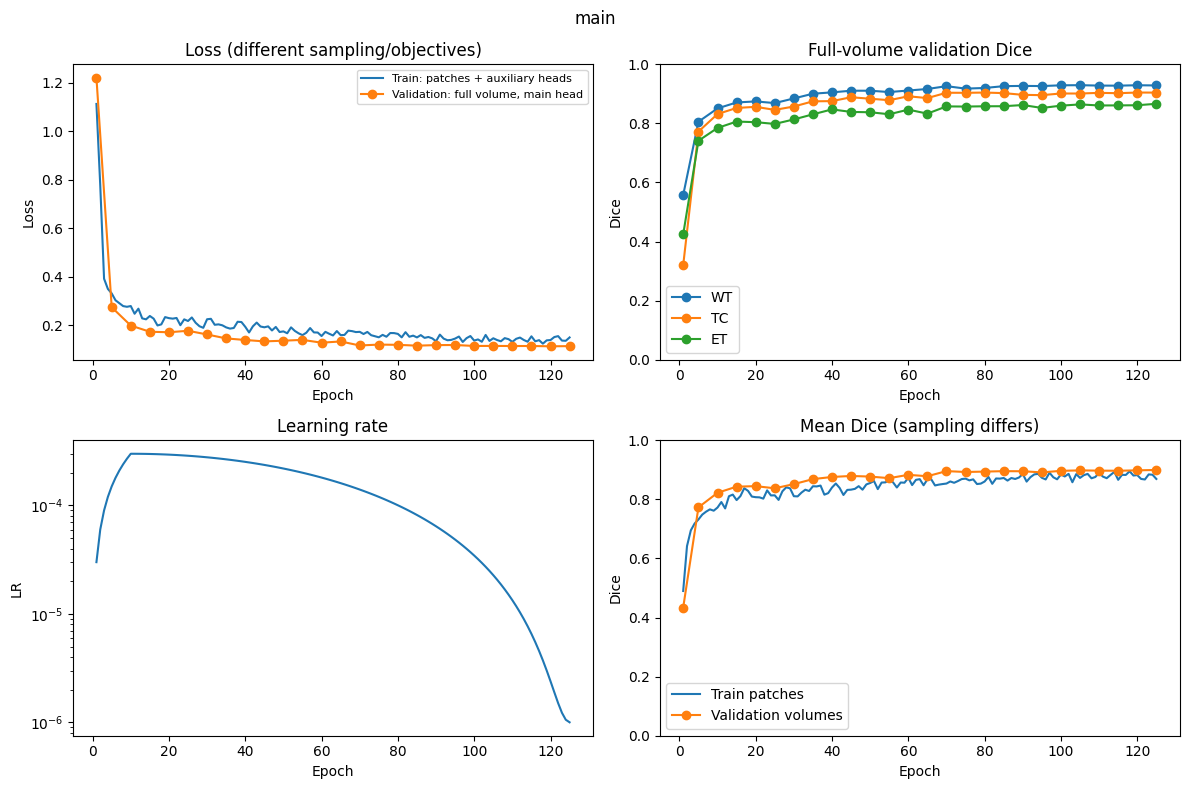

In [14]:
if cfg.run_training:
    main_history = train_experiment("main", resume=cfg.resume_path)
    if cfg.run_baseline:
        baseline_history = train_experiment("baseline", variant="baseline")
    if cfg.run_student:
        teacher, _ = load_best("main")
        student_history = train_experiment("student", teacher=teacher, epochs=cfg.student_epochs)
        del teacher
else:
    print(
        "Training disabled. Evaluation requires existing best.pt checkpoints in the selected output directory."
    )

experiment_names = (
    ["main"] + (["baseline"] if cfg.run_baseline else []) + (["student"] if cfg.run_student else [])
)


def plot_history(name):
    h = pd.read_csv(OUT / name / "history.csv")
    v = h.dropna(subset=["val_mean_dice"])
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes[0, 0].plot(h.epoch, h.train_loss, label="Train: patches + auxiliary heads")
    axes[0, 0].plot(v.epoch, v.val_loss, "o-", label="Validation: full volume, main head")
    axes[0, 0].set(title="Loss (different sampling/objectives)", xlabel="Epoch", ylabel="Loss")
    axes[0, 0].legend(fontsize=8)
    for r in REGIONS:
        axes[0, 1].plot(v.epoch, v[f"val_dice_{r}"], "o-", label=r)
    axes[0, 1].set(title="Full-volume validation Dice", xlabel="Epoch", ylabel="Dice", ylim=(0, 1))
    axes[0, 1].legend()
    axes[1, 0].plot(h.epoch, h.lr)
    axes[1, 0].set(title="Learning rate", xlabel="Epoch", ylabel="LR", yscale="log")
    axes[1, 1].plot(h.epoch, h.train_patch_dice, label="Train patches")
    axes[1, 1].plot(v.epoch, v.val_mean_dice, "o-", label="Validation volumes")
    axes[1, 1].set(title="Mean Dice (sampling differs)", xlabel="Epoch", ylabel="Dice", ylim=(0, 1))
    axes[1, 1].legend()
    fig.suptitle(name + (" — SMOKE ONLY" if cfg.smoke_test else ""))
    fig.tight_layout()
    fig.savefig(OUT / name / "learning_curves.png", dpi=180)
    plt.show()


for name in experiment_names:
    plot_history(name)

In [15]:
EXPORT_DIR = OUT / "exported_models"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

for name in experiment_names:
    best_path = OUT / name / "best.pt"
    if not best_path.is_file():
        print(f"Skipping {name}: no trained checkpoint at {best_path}")
        continue

    trained_model, best_ckpt = load_best(name)
    export_path = EXPORT_DIR / f"{name}_model.pth"
    torch.save(
        {
            "state_dict": {k: v.detach().cpu() for k, v in trained_model.state_dict().items()},
            "base": best_ckpt["base"],
            "variant": best_ckpt["variant"],
            "epoch": best_ckpt["epoch"],
            "val_score": best_ckpt["val_score"],
        },
        export_path,
    )
    print(f"Saved {name} → {export_path} (validation Dice: {best_ckpt['val_score']:.4f})")
    del trained_model

Saved main → /kaggle/working/moreg/full/exported_models/main_model.pth (validation Dice: 0.8997)


In [16]:
MODEL_NAME = "main"
MODEL_FILE = EXPORT_DIR / f"{MODEL_NAME}_model.pth"
if not MODEL_FILE.is_file():
    raise FileNotFoundError(f"Export not found: {MODEL_FILE}. Run the saving cell first.")

saved = torch.load(MODEL_FILE, map_location="cpu", weights_only=True)
loaded_model = MoReGSeg(saved["base"], saved["variant"]).to(DEVICE)
loaded_model.load_state_dict(saved["state_dict"], strict=True)
loaded_model.eval()
print(f"Loaded {MODEL_NAME} model from {MODEL_FILE}")
print(f"Selected epoch: {saved['epoch']} | validation Dice: {saved['val_score']:.4f}")

Loaded main model from /kaggle/working/moreg/full/exported_models/main_model.pth
Selected epoch: 125 | validation Dice: 0.8997


In [17]:
def bootstrap_mean(values, seed=None):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if not len(values):
        return np.nan, np.nan
    rng = np.random.default_rng(cfg.seed if seed is None else seed)
    means = [
        rng.choice(values, len(values), replace=True).mean() for _ in range(cfg.bootstrap_samples)
    ]
    return tuple(np.percentile(means, [2.5, 97.5]))


def summarize(df):
    metrics = [
        "dice",
        "iou",
        "precision",
        "recall",
        "specificity",
        "voxel_accuracy",
        "hd95_mm",
        "surface_dice",
    ]
    rows = []
    for r, group in df.groupby("region", sort=False):
        for metric in metrics:
            values = group[metric].to_numpy(dtype=float)
            finite = values[np.isfinite(values)]
            low, high = bootstrap_mean(finite)
            rows.append(
                dict(
                    region=r,
                    metric=metric,
                    mean=float(finite.mean()) if len(finite) else np.nan,
                    median=float(np.median(finite)) if len(finite) else np.nan,
                    std=float(finite.std(ddof=1)) if len(finite) > 1 else np.nan,
                    ci95_low=low,
                    ci95_high=high,
                    n_patients=len(values),
                    n_finite=len(finite),
                    n_nan=int(np.isnan(values).sum()),
                    n_infinite=int(np.isinf(values).sum()),
                    population="finite cases only" if np.isinf(values).any() else "defined cases",
                )
            )
        present = group.loc[group.gt_present, "dice"].to_numpy()
        low, high = bootstrap_mean(present)
        rows.append(
            dict(
                region=r,
                metric="dice_GT_present",
                mean=np.mean(present) if len(present) else np.nan,
                ci95_low=low,
                ci95_high=high,
                n_patients=len(group),
                n_finite=len(present),
                n_nan=0,
                n_infinite=0,
                population="GT-present cases only",
            )
        )
    return pd.DataFrame(rows)

In [18]:
def plot_test(df, summary, examples, folder):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, metric, title in zip(
        axes[0],
        ["dice", "iou", "hd95_mm"],
        ["Dice by patient", "IoU by patient", "HD95 (finite cases only)"],
    ):
        arrays = [
            df.loc[df.region == r, metric].replace([np.inf, -np.inf], np.nan).dropna().to_numpy()
            for r in REGIONS
        ]
        ax.boxplot([a if len(a) else [np.nan] for a in arrays], tick_labels=REGIONS, showmeans=True)
        ax.set(title=title, ylabel="mm" if metric == "hd95_mm" else metric)
        if metric != "hd95_mm":
            ax.set_ylim(0, 1.03)
        else:
            ax.text(
                0.02,
                0.96,
                f"Infinite failures: {int(np.isinf(df[metric]).sum())}",
                transform=ax.transAxes,
                va="top",
            )
    for r in REGIONS:
        d = df[df.region == r]
        axes[1, 0].scatter(d.gt_ml, d.dice, s=15, alpha=0.6, label=r)
    axes[1, 0].set(
        xlabel="GT tumor volume (mL)",
        ylabel="Dice",
        title="Small-tumor performance",
        xscale="symlog",
        ylim=(0, 1.03),
    )
    axes[1, 0].legend()
    sm = summary[summary.metric == "dice"].set_index("region").loc[list(REGIONS)]
    lo = np.maximum(0, sm["mean"] - sm.ci95_low)
    hi = np.maximum(0, sm.ci95_high - sm["mean"])
    axes[1, 1].bar(
        REGIONS,
        sm["mean"],
        yerr=np.stack([lo, hi]),
        capsize=5,
        color=["#5470c6", "#58a687", "#cc785c"],
    )
    axes[1, 1].set(title="Patient bootstrap 95% CI", ylabel="Mean Dice", ylim=(0, 1.05))
    latency = df.drop_duplicates("case_id").inference_seconds
    axes[1, 2].hist(latency, bins=min(15, len(latency)))
    axes[1, 2].set(
        title="Inference incl. tiling/CPU merge/TTA", xlabel="Seconds per case", ylabel="Patients"
    )
    fig.tight_layout()
    fig.savefig(folder / "test_dashboard.png", dpi=180)
    plt.show()
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
    for ax, r in zip(axes, REGIONS):
        d = df[df.region == r]
        cm = np.array([[d.tn.sum(), d.fp.sum()], [d.fn.sum(), d.tp.sum()]], dtype=float)
        normalized = cm / np.maximum(cm.sum(1, keepdims=True), 1)
        ax.imshow(normalized, vmin=0, vmax=1, cmap="Blues")
        for i, j in itertools.product(range(2), repeat=2):
            ax.text(
                j,
                i,
                f"{cm[i,j]:,.0f}\n({normalized[i,j]:.3f})",
                ha="center",
                va="center",
                color="white" if normalized[i, j] > 0.6 else "black",
                fontsize=8,
            )
        ax.set(
            xticks=[0, 1],
            yticks=[0, 1],
            xticklabels=["Absent", "Present"],
            yticklabels=["Absent", "Present"],
            xlabel="Predicted",
            ylabel="Ground truth",
            title=r,
        )
    fig.suptitle("Voxel confusion matrices: rows normalized; counts pooled across patients")
    fig.tight_layout()
    fig.savefig(folder / "confusion_matrices.png", dpi=180)
    plt.show()

    cmap = ListedColormap(["black", "#4bb3fd", "#f2c14e", "#ef476f"])
    for cid, flair, gt, pred in examples:
        # Slice with largest GT tumor area, stated selection rule; patient is not cherry-picked.
        z = int(np.argmax((gt > 0).sum((0, 1))))

        def remap(a):
            return np.select([a == 1, a == 2, a == 4], [1, 2, 3], 0)

        error = np.zeros_like(gt)
        error[(gt == 0) & (pred > 0)] = 1
        error[(gt > 0) & (pred == 0)] = 2
        error[(gt > 0) & (pred > 0) & (gt != pred)] = 3
        fig, axes = plt.subplots(1, 4, figsize=(14, 4))
        for ax in axes:
            ax.imshow(flair[:, :, z].T, cmap="gray", origin="lower")
            ax.axis("off")
        axes[1].imshow(
            np.ma.masked_equal(remap(gt[:, :, z].T), 0),
            cmap=cmap,
            vmin=0,
            vmax=3,
            alpha=0.7,
            origin="lower",
        )
        axes[2].imshow(
            np.ma.masked_equal(remap(pred[:, :, z].T), 0),
            cmap=cmap,
            vmin=0,
            vmax=3,
            alpha=0.7,
            origin="lower",
        )
        axes[3].imshow(
            np.ma.masked_equal(error[:, :, z].T, 0),
            cmap=ListedColormap(["black", "red", "cyan", "yellow"]),
            vmin=0,
            vmax=3,
            alpha=0.8,
            origin="lower",
        )
        for ax, title in zip(
            axes,
            [
                "FLAIR",
                "GT: blue=NCR, gold=ED, pink=ET",
                "Prediction",
                "Errors: red=FP, cyan=FN, yellow=subtype",
            ],
        ):
            ax.set_title(title, fontsize=9)
        fig.suptitle(f"{cid} | axial z={z} (largest GT tumor slice)")
        fig.tight_layout()
        fig.savefig(folder / f"{cid}_overlay.png", dpi=180)
        plt.show()

Full-volume evaluation:   0%|          | 0/188 [00:00<?, ?it/s]

main {'mean_patient_macro_dice': 0.8942883757870004, 'ci95_low': np.float64(0.8778383730746265), 'ci95_high': np.float64(0.9093110459895954), 'n_test_patients': 188, 'selected_epoch': 125, 'validation_dice_at_selection': 0.8997318122859015, 'threshold': 0.5, 'tta': False, 'surface_tolerance_mm': 1.0, 'smoke_only': False, 'hd95_infinite_failures': 3, 'inference_seconds_median': 1.5341250840010616}


,region,metric,mean,median,std,ci95_low,ci95_high,n_patients,n_finite,n_nan,n_infinite,population
0,WT,dice,0.915856,0.945685,0.088365,0.902537,0.927679,188,188,0,0,defined cases
1,WT,iou,0.854902,0.896966,0.126109,0.836768,0.871729,188,188,0,0,defined cases
2,WT,precision,0.926027,0.958182,0.091642,0.911903,0.938883,188,188,0,0,defined cases
3,WT,recall,0.918215,0.952602,0.105997,0.902137,0.931945,188,188,0,0,defined cases
4,WT,specificity,0.999348,0.999598,0.000910,0.999200,0.999464,188,188,0,0,defined cases
5,WT,voxel_accuracy,0.998567,0.998995,0.001472,0.998345,0.998757,188,188,0,0,defined cases
6,WT,hd95_mm,12.248297,2.828427,22.460524,9.389938,15.528126,188,188,0,0,defined cases
7,WT,surface_dice,0.823642,0.867995,0.151775,0.802480,0.843937,188,188,0,0,defined cases
8,WT,dice_GT_present,0.915856,NaN,NaN,0.902537,0.927679,188,188,0,0,GT-present cases only
9,TC,dice,0.907031,0.954069,0.151227,0.883289,0.926128,188,188,0,0,defined cases


,gt_absent,empty_false_positives
region,,
ET,5,2
TC,1,0
WT,0,0


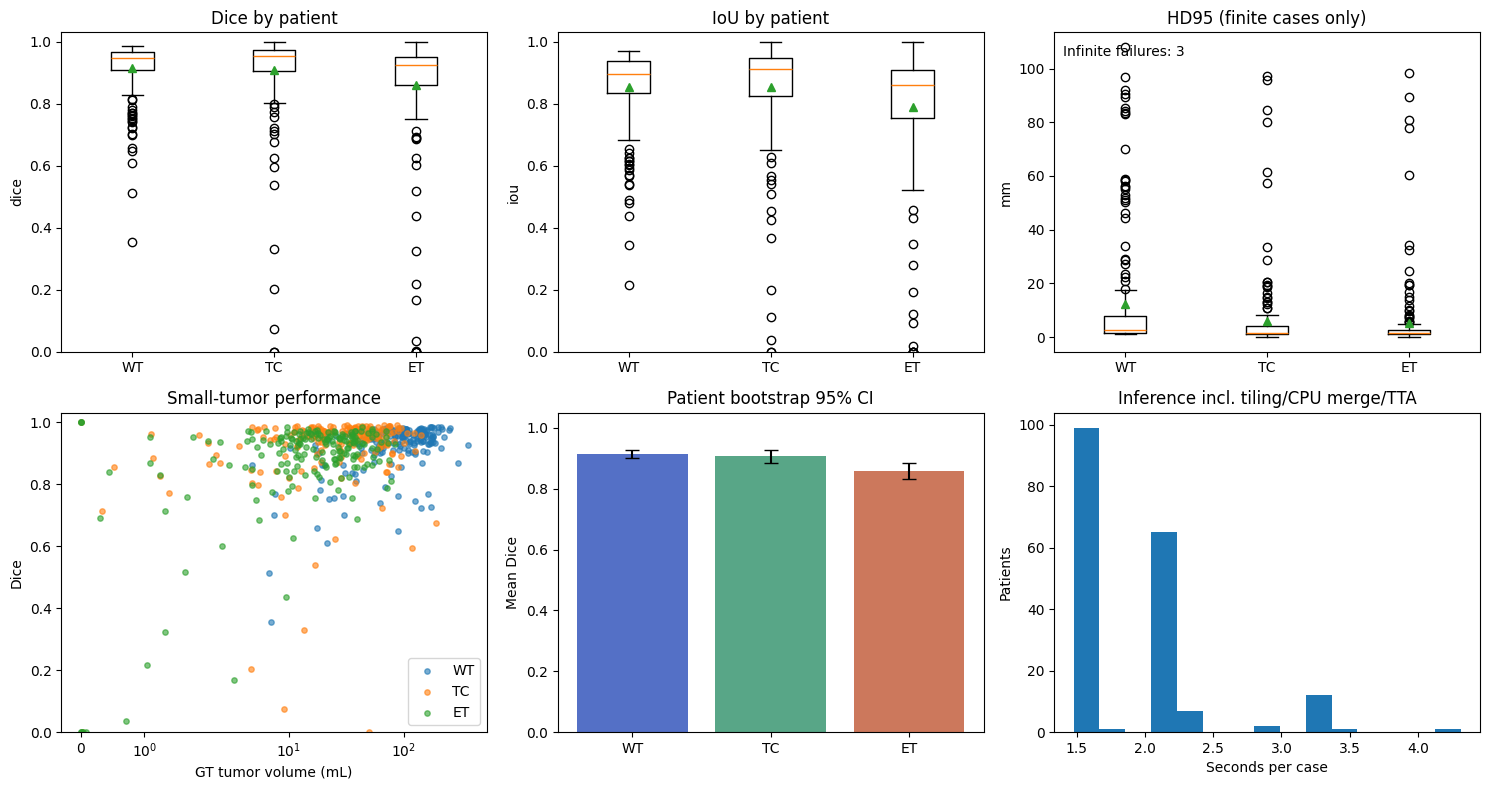

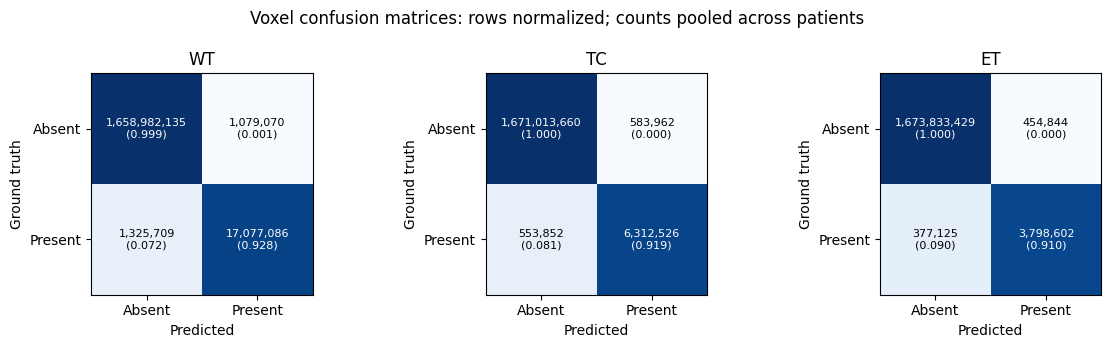

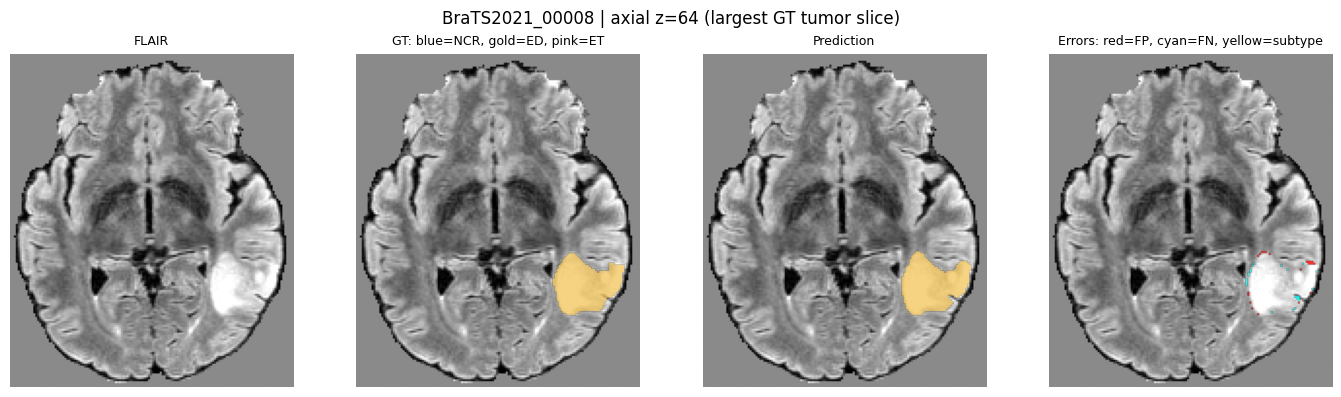

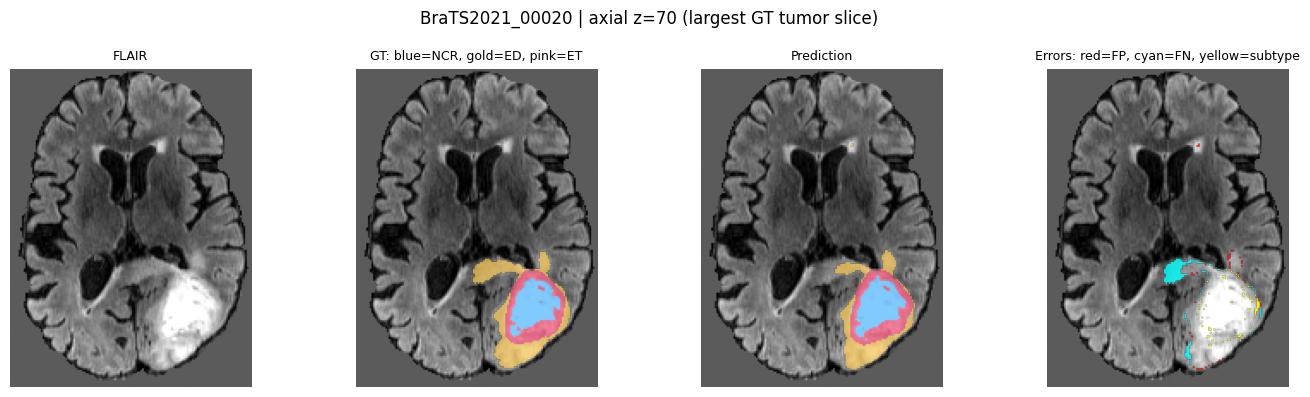

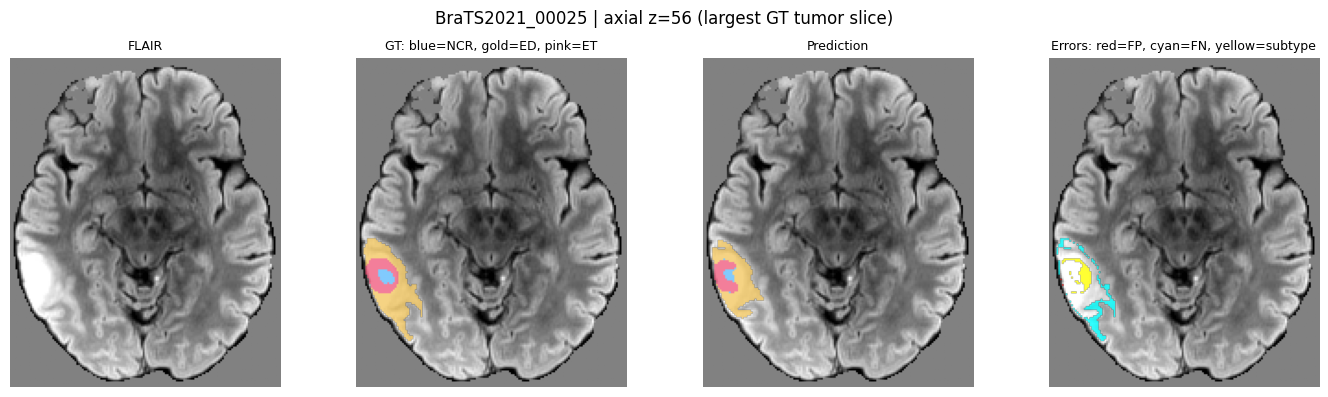

In [19]:
test_results = {}
for name in experiment_names:
    model, checkpoint = load_best(name)
    folder = OUT / name / "test"
    folder.mkdir(parents=True, exist_ok=True)
    metrics, val_loss, examples = evaluate(
        model, files["test"], surfaces=True, out_dir=folder, save_examples=cfg.save_nifti_count
    )
    metrics.to_csv(folder / "patient_metrics.csv", index=False)
    summary = summarize(metrics)
    summary.to_csv(folder / "metric_summary.csv", index=False)
    patient_macro = metrics.pivot(index="case_id", columns="region", values="dice").mean(axis=1)
    low, high = bootstrap_mean(patient_macro)
    overview = dict(
        mean_patient_macro_dice=float(patient_macro.mean()),
        ci95_low=low,
        ci95_high=high,
        n_test_patients=len(patient_macro),
        selected_epoch=checkpoint["epoch"],
        validation_dice_at_selection=checkpoint["val_score"],
        threshold=cfg.threshold,
        tta=cfg.tta,
        surface_tolerance_mm=cfg.surface_tolerance_mm,
        smoke_only=cfg.smoke_test,
        hd95_infinite_failures=int(np.isinf(metrics.hd95_mm).sum()),
        inference_seconds_median=float(
            metrics.drop_duplicates("case_id").inference_seconds.median()
        ),
    )
    atomic_csv(pd.DataFrame([overview]), folder / "overview.csv")
    empty_report = metrics.groupby("region").agg(
        gt_absent=("gt_present", lambda a: int((~a).sum())),
        empty_false_positives=("empty_false_positive", "sum"),
    )
    empty_report.to_csv(folder / "empty_region_report.csv")
    print(name, overview)
    display(summary)
    display(empty_report)
    plot_test(metrics, summary, examples, folder)
    test_results[name] = metrics
    del model, examples
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()